In [52]:
import os
import re
import time
import warnings
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import gensim
import sklearn

from collections import Counter

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from nltk.sentiment import SentimentIntensityAnalyzer

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)

from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer
)

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix
)

from sklearn.pipeline import Pipeline

from sklearn.decomposition import PCA

from gensim.models import Word2Vec

import joblib

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [53]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Random seed:", SEED)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("NLTK:", nltk.__version__)
print("Gensim:", gensim.__version__)

Random seed: 42
Pandas: 3.0.6
NumPy: 2.4.6
Scikit-learn: 1.9.1
NLTK: 3.9.4
Gensim: 4.4.0


In [54]:
resources = [
    "stopwords",
    "punkt",
    "vader_lexicon",
    "averaged_perceptron_tagger"
]

for resource in resources:
    nltk.download(resource, quiet=True)

# Additional resources required by newer NLTK versions
for resource in [
    "punkt_tab",
    "averaged_perceptron_tagger_eng"
]:
    nltk.download(resource, quiet=True)

print("NLTK resources downloaded successfully!")

NLTK resources downloaded successfully!


In [55]:
df = pd.read_csv("Tweets.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (14640, 15)


,tweet_id,airline_sentiment,airline_sentiment_confidence,negativereason,negativereason_confidence,airline,airline_sentiment_gold,name,negativereason_gold,retweet_count,text,tweet_coord,tweet_created,tweet_location,user_timezone
0,570306133677760513,neutral,1.0000,NaN,NaN,Virgin America,NaN,cairdin,NaN,0,@VirginAmerica What @dhepburn said.,NaN,2015-02-24 11:35:52 -0800,NaN,Eastern Time (US & Canada)
1,570301130888122368,positive,0.3486,NaN,0.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica plus you've added commercials t...,NaN,2015-02-24 11:15:59 -0800,NaN,Pacific Time (US & Canada)
2,570301083672813571,neutral,0.6837,NaN,NaN,Virgin America,NaN,yvonnalynn,NaN,0,@VirginAmerica I didn't today... Must mean I n...,NaN,2015-02-24 11:15:48 -0800,Lets Play,Central Time (US & Canada)
3,570301031407624196,negative,1.0000,Bad Flight,0.7033,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica it's really aggressive to blast...,NaN,2015-02-24 11:15:36 -0800,NaN,Pacific Time (US & Canada)
4,570300817074462722,negative,1.0000,Can't Tell,1.0000,Virgin America,NaN,jnardino,NaN,0,@VirginAmerica and it's a really big bad thing...,NaN,2015-02-24 11:14:45 -0800,NaN,Pacific Time (US & Canada)


In [57]:
print("\nShape:")
print(df.shape)


Shape:
(14640, 15)


In [58]:
print("\nData Types:")
print(df.dtypes)


Data Types:
tweet_id                          int64
airline_sentiment                   str
airline_sentiment_confidence    float64
negativereason                      str
negativereason_confidence       float64
airline                             str
airline_sentiment_gold              str
name                                str
negativereason_gold                 str
retweet_count                     int64
text                                str
tweet_coord                         str
tweet_created                       str
tweet_location                      str
user_timezone                       str
dtype: object


In [59]:
print("\nMissing Values:")
print(df.isnull().sum())


Missing Values:
tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
negativereason                   5462
negativereason_confidence        4118
airline                             0
airline_sentiment_gold          14600
name                                0
negativereason_gold             14608
retweet_count                       0
text                                0
tweet_coord                     13621
tweet_created                       0
tweet_location                   4733
user_timezone                    4820
dtype: int64


In [60]:
print("\nDuplicate Tweets:")
print(df["text"].duplicated().sum())


Duplicate Tweets:
213


In [61]:
print("\nSentiment Distribution:")
print(df["airline_sentiment"].value_counts())


Sentiment Distribution:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


In [62]:
df = df.dropna(subset=[
    "text",
    "airline_sentiment",
    "airline"
])

df = df.drop_duplicates(
    subset=["text", "airline_sentiment", "airline"]
)

df = df.reset_index(drop=True)

print("After cleaning:")
print(df.shape)

print("Missing values:")
print(df.isnull().sum())

print("Duplicates:")
print(df.duplicated().sum())

After cleaning:
(14452, 15)
Missing values:
tweet_id                            0
airline_sentiment                   0
airline_sentiment_confidence        0
negativereason                   5365
negativereason_confidence        4034
airline                             0
airline_sentiment_gold          14412
name                                0
negativereason_gold             14420
retweet_count                       0
text                                0
tweet_coord                     13448
tweet_created                       0
tweet_location                   4673
user_timezone                    4759
dtype: int64
Duplicates:
0


In [63]:
for i, tweet in enumerate(df["text"].head(5), start=1):

    print(f"\nTweet {i}")
    print("-" * 80)
    print(tweet)


Tweet 1
--------------------------------------------------------------------------------
@VirginAmerica What @dhepburn said.

Tweet 2
--------------------------------------------------------------------------------
@VirginAmerica plus you've added commercials to the experience... tacky.

Tweet 3
--------------------------------------------------------------------------------
@VirginAmerica I didn't today... Must mean I need to take another trip!

Tweet 4
--------------------------------------------------------------------------------
@VirginAmerica it's really aggressive to blast obnoxious "entertainment" in your guests' faces &amp; they have little recourse

Tweet 5
--------------------------------------------------------------------------------
@VirginAmerica and it's a really big bad thing about it


# Task 1: NLP Fundamentals

## What is Natural Language Processing?

Natural Language Processing (NLP) is a branch of
Artificial Intelligence that helps computers understand,
process and analyse human language.

Computers cannot directly understand unstructured human
language in the same way humans do. NLP converts text
into a structured representation that machines can process.

### Applications of NLP

1. Search Engines – Understanding search queries.
2. Spam Filtering – Detecting unwanted emails.
3. Chatbots – Answering customer questions.
4. Machine Translation – Translating Gujarati, Hindi
   and English languages.
5. Sentiment Analysis – Understanding customer opinions.

### Indian Use Cases

- Indian banking chatbots can answer customer questions
  in Hindi, Gujarati and other regional languages.
- E-commerce companies can analyse customer reviews
  to understand product satisfaction.

## Common NLP Tasks

| Task | Description | Example |
|---|---|---|
| Text Classification | Assigning a category | Spam detection |
| Sentiment Analysis | Identifying emotions | Positive review |
| NER | Identifying named entities | Person, location |
| POS Tagging | Identifying grammatical roles | Noun, verb |
| Machine Translation | Translating languages | English to Hindi |
| Summarisation | Shortening long text | News summary |
| Question Answering | Answering questions | Chatbot |

## NLP Approaches

| Approach | Meaning | Example |
|---|---|---|
| Heuristic | Handwritten rules | Positive/negative word lists |
| API-based | Ready-made sentiment engine | VADER |
| Machine Learning | Learns from labelled data | TF-IDF + Logistic Regression |

## NLP Pipeline

Data Collection
      ↓
Text Cleaning
      ↓
Tokenisation
      ↓
Stop-word Removal
      ↓
Feature Extraction
      ↓
Model Training
      ↓
Model Evaluation
      ↓
Deployment

In this project, airline tweets are collected from Kaggle,
cleaned using RegEx, converted into numerical features,
classified using machine learning and deployed using Streamlit.

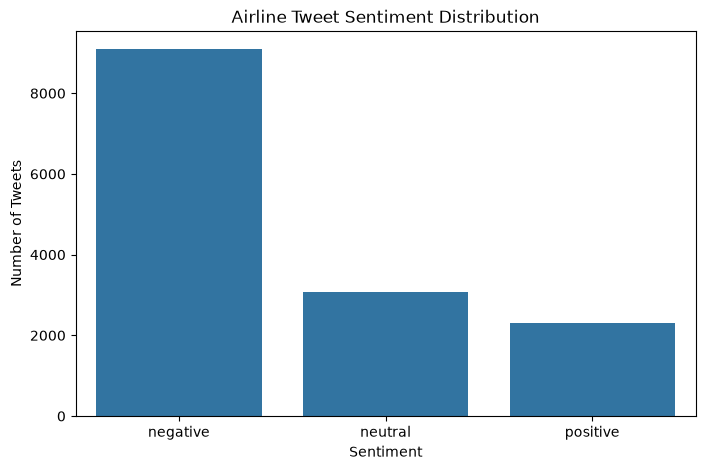

In [64]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="airline_sentiment",
    order=["negative", "neutral", "positive"]
)

plt.title("Airline Tweet Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.show()

In [65]:
sentiment_percentage = (
    df["airline_sentiment"]
    .value_counts(normalize=True) * 100
)

print(sentiment_percentage.round(2))

airline_sentiment
negative    62.88
neutral     21.22
positive    15.90
Name: proportion, dtype: float64


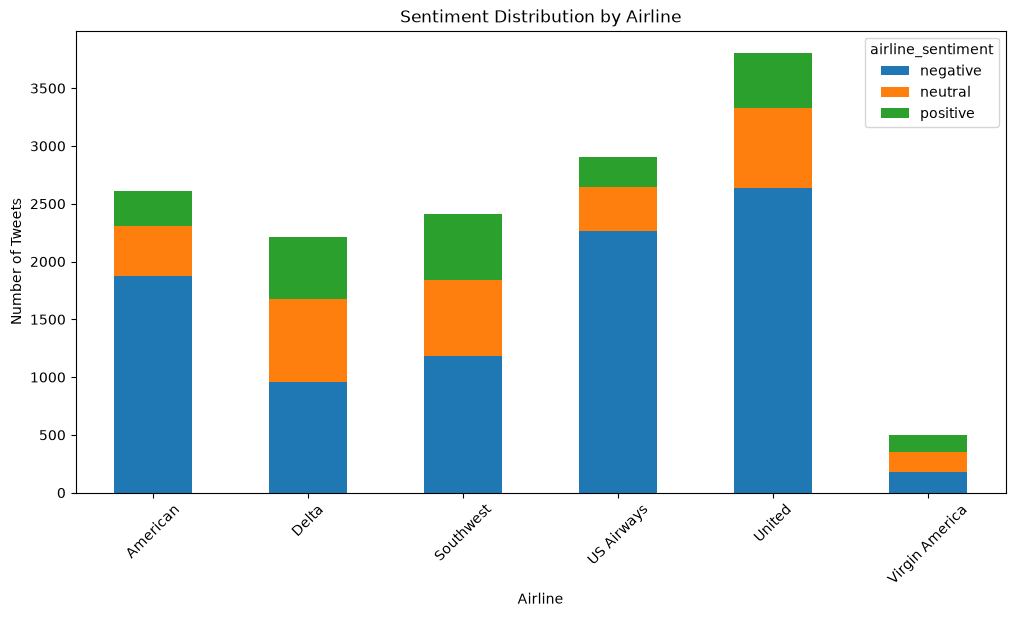

In [66]:
airline_sentiment = pd.crosstab(
    df["airline"],
    df["airline_sentiment"]
)

airline_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Sentiment Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)

plt.show()

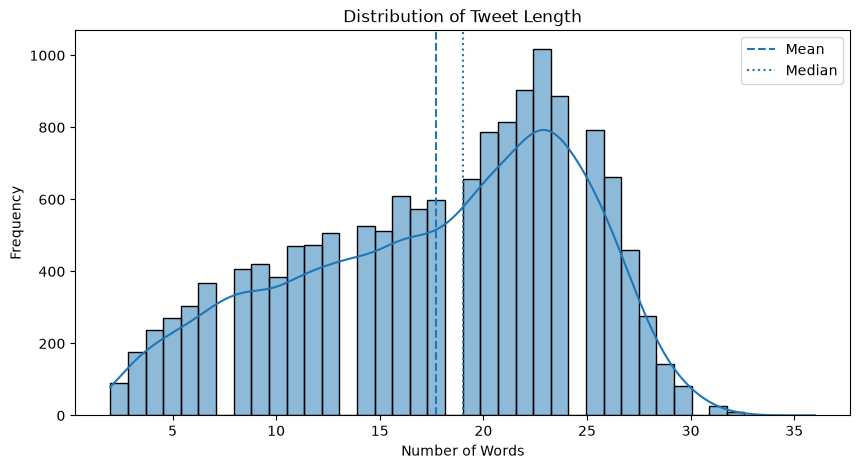

Mean: 17.71104345419319
Median: 19.0


In [67]:
df["tweet_length"] = df["text"].apply(
    lambda x: len(str(x).split())
)

plt.figure(figsize=(10, 5))

sns.histplot(
    df["tweet_length"],
    bins=40,
    kde=True
)

plt.axvline(
    df["tweet_length"].mean(),
    linestyle="--",
    label="Mean"
)

plt.axvline(
    df["tweet_length"].median(),
    linestyle=":",
    label="Median"
)

plt.title("Distribution of Tweet Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.legend()
plt.show()

print("Mean:", df["tweet_length"].mean())
print("Median:", df["tweet_length"].median())

In [68]:
challenge_keywords = {
    "negation": ["not", "never", "no"],
    "sarcasm": ["great", "awesome", "wonderful"],
    "slang": ["lol", "omg", "ugh"],
    "special_symbols": ["!", "#", "$", ":)"]
}

for category, keywords in challenge_keywords.items():

    pattern = "|".join(
        re.escape(word) for word in keywords
    )

    result = df[
        df["text"].str.contains(
            pattern,
            case=False,
            na=False
        )
    ]

    print("\nCATEGORY:", category.upper())

    display(
        result[[
            "text",
            "airline_sentiment"
        ]].head(3)
    )


CATEGORY: NEGATION


,text,airline_sentiment
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive



CATEGORY: SARCASM


,text,airline_sentiment
12,@VirginAmerica This is such a great deal! Alre...,positive
16,@VirginAmerica So excited for my first cross c...,positive
19,@VirginAmerica you know what would be amazingl...,positive



CATEGORY: SLANG


,text,airline_sentiment
51,@VirginAmerica @ladygaga @carrieunderwood Juli...,positive
66,@VirginAmerica heyyyy guyyyys.. been trying to...,negative
103,@virginamerica how's a direct flight FLL-&gt;S...,negative



CATEGORY: SPECIAL_SYMBOLS


,text,airline_sentiment
2,@VirginAmerica I didn't today... Must mean I n...,neutral
5,@VirginAmerica seriously would pay $30 a fligh...,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",positive


## Class Imbalance

The airline sentiment dataset is imbalanced.

Negative tweets are more common than neutral and
positive tweets.

Therefore, accuracy alone is not sufficient to evaluate
the model.

Macro-F1 is important because it gives equal importance
to all sentiment classes.

# Task 2: Text Cleaning

We will apply the following cleaning operations:

1. Convert text into lowercase.
2. Remove URLs.
3. Remove user mentions.
4. Remove hashtag symbols but retain hashtag words.
5. Remove numbers.
6. Remove punctuation.
7. Remove extra spaces.

We will preserve negation words because words such as
not, no and never can completely change sentiment.

In [69]:
sample_text = """
WOW!!! I am NOT happy with this flight.
Visit https://example.com @airline #Delayed123
"""

print("Original:")
print(sample_text)

# Lowercase
print("\nLowercase:")
print(sample_text.lower())

# Remove URLs
print("\nRemove URLs:")
print(re.sub(r"https?://\S+", "", sample_text))

# Remove mentions
print("\nRemove Mentions:")
print(re.sub(r"@\w+", "", sample_text))

# Extract hashtag words
print("\nHashtag words:")
print(re.findall(r"#(\w+)", sample_text))

# Remove hashtag symbols
print("\nRemove hashtag symbols:")
print(re.sub(r"#(\w+)", r"\1", sample_text))

# Remove numbers
print("\nRemove numbers:")
print(re.sub(r"\d+", "", sample_text))

# Remove punctuation
print("\nRemove punctuation:")
print(re.sub(r"[^a-z\s]", "", sample_text.lower()))

# Remove extra spaces
print("\nRemove extra spaces:")
print(re.sub(r"\s+", " ", sample_text).strip())

Original:

WOW!!! I am NOT happy with this flight.
Visit https://example.com @airline #Delayed123


Lowercase:

wow!!! i am not happy with this flight.
visit https://example.com @airline #delayed123


Remove URLs:

WOW!!! I am NOT happy with this flight.
Visit  @airline #Delayed123


Remove Mentions:

WOW!!! I am NOT happy with this flight.
Visit https://example.com  #Delayed123


Hashtag words:
['Delayed123']

Remove hashtag symbols:

WOW!!! I am NOT happy with this flight.
Visit https://example.com @airline Delayed123


Remove numbers:

WOW!!! I am NOT happy with this flight.
Visit https://example.com @airline #Delayed


Remove punctuation:

wow i am not happy with this flight
visit httpsexamplecom airline delayed


Remove extra spaces:
WOW!!! I am NOT happy with this flight. Visit https://example.com @airline #Delayed123


In [70]:
def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(
        r"https?://\S+|www\.\S+",
        "",
        text
    )

    # Remove mentions
    text = re.sub(
        r"@\w+",
        "",
        text
    )

    # Keep hashtag words
    text = re.sub(
        r"#(\w+)",
        r"\1",
        text
    )

    # Remove numbers
    text = re.sub(
        r"\d+",
        "",
        text
    )

    # Remove punctuation and special characters
    text = re.sub(
        r"[^a-z\s]",
        " ",
        text
    )

    # Remove extra spaces
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text

In [71]:
df["clean_text"] = df["text"].apply(clean_text)

display(
    df[[
        "text",
        "clean_text"
    ]].head(10)
)

,text,clean_text
0,@VirginAmerica What @dhepburn said.,what said
1,@VirginAmerica plus you've added commercials t...,plus you ve added commercials to the experienc...
2,@VirginAmerica I didn't today... Must mean I n...,i didn t today must mean i need to take anothe...
3,@VirginAmerica it's really aggressive to blast...,it s really aggressive to blast obnoxious ente...
4,@VirginAmerica and it's a really big bad thing...,and it s a really big bad thing about it
5,@VirginAmerica seriously would pay $30 a fligh...,seriously would pay a flight for seats that di...
6,"@VirginAmerica yes, nearly every time I fly VX...",yes nearly every time i fly vx this ear worm w...
7,@VirginAmerica Really missed a prime opportuni...,really missed a prime opportunity for men with...
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",well i didn t but now i do d
9,"@VirginAmerica it was amazing, and arrived an ...",it was amazing and arrived an hour early you r...


In [72]:
empty_tweets = df["clean_text"].eq("")

print(
    "Empty tweets after cleaning:",
    empty_tweets.sum()
)

print(
    "Percentage:",
    round(empty_tweets.mean() * 100, 2),
    "%"
)

# Remove tweets that become completely empty
df = df[~empty_tweets].copy()

df = df.reset_index(drop=True)

print("Final dataset shape:", df.shape)

Empty tweets after cleaning: 0
Percentage: 0.0 %
Final dataset shape: (14452, 17)


In [73]:
df["tokens"] = df["clean_text"].apply(
    word_tokenize
)

display(
    df[[
        "clean_text",
        "tokens"
    ]].head()
)

,clean_text,tokens
0,what said,"[what, said]"
1,plus you ve added commercials to the experienc...,"[plus, you, ve, added, commercials, to, the, e..."
2,i didn t today must mean i need to take anothe...,"[i, didn, t, today, must, mean, i, need, to, t..."
3,it s really aggressive to blast obnoxious ente...,"[it, s, really, aggressive, to, blast, obnoxio..."
4,and it s a really big bad thing about it,"[and, it, s, a, really, big, bad, thing, about..."


In [74]:
stop_words = set(stopwords.words("english"))

negation_words = {
    "no",
    "not",
    "nor",
    "never"
}

stop_words = stop_words - negation_words

def remove_stopwords(tokens):

    return [
        word
        for word in tokens
        if word not in stop_words
    ]

df["filtered_tokens"] = df["tokens"].apply(
    remove_stopwords
)

display(
    df[[
        "tokens",
        "filtered_tokens"
    ]].head()
)

,tokens,filtered_tokens
0,"[what, said]",[said]
1,"[plus, you, ve, added, commercials, to, the, e...","[plus, added, commercials, experience, tacky]"
2,"[i, didn, t, today, must, mean, i, need, to, t...","[today, must, mean, need, take, another, trip]"
3,"[it, s, really, aggressive, to, blast, obnoxio...","[really, aggressive, blast, obnoxious, enterta..."
4,"[and, it, s, a, really, big, bad, thing, about...","[really, big, bad, thing]"


In [75]:
example = "not happy with the delay"

tokens = word_tokenize(example)

filtered = remove_stopwords(tokens)

print("Original:", tokens)
print("After stop-word removal:", filtered)

Original: ['not', 'happy', 'with', 'the', 'delay']
After stop-word removal: ['not', 'happy', 'delay']


In [76]:
all_tokens_before = [
    word
    for tokens in df["tokens"]
    for word in tokens
]

all_tokens_after = [
    word
    for tokens in df["filtered_tokens"]
    for word in tokens
]

before_vocab = set(all_tokens_before)
after_vocab = set(all_tokens_after)

print("Vocabulary before filtering:", len(before_vocab))
print("Vocabulary after filtering:", len(after_vocab))

frequency = Counter(all_tokens_after)

print(
    "Words appearing only once:",
    sum(1 for word, count in frequency.items() if count == 1)
)

Vocabulary before filtering: 11212
Vocabulary after filtering: 11068
Words appearing only once: 5535


In [77]:
for sentiment in [
    "negative",
    "neutral",
    "positive"
]:

    sentiment_tokens = [
        word
        for tokens in df.loc[
            df["airline_sentiment"] == sentiment,
            "filtered_tokens"
        ]
        for word in tokens
    ]

    print(f"\nTop 20 words: {sentiment.upper()}")

    display(
        pd.DataFrame(
            Counter(sentiment_tokens)
            .most_common(20),
            columns=["Word", "Frequency"]
        )
    )


Top 20 words: NEGATIVE


,Word,Frequency
0,flight,2925
1,not,1386
2,no,1304
3,get,985
4,cancelled,910
5,service,744
6,hours,649
7,help,613
8,hold,608
9,customer,607



Top 20 words: NEUTRAL


,Word,Frequency
0,flight,607
1,get,236
2,please,181
3,help,170
4,flights,169
5,need,162
6,not,155
7,thanks,154
8,dm,131
9,would,122



Top 20 words: POSITIVE


,Word,Frequency
0,thanks,581
1,thank,434
2,flight,381
3,great,234
4,service,161
5,love,134
6,customer,113
7,get,113
8,much,108
9,guys,108


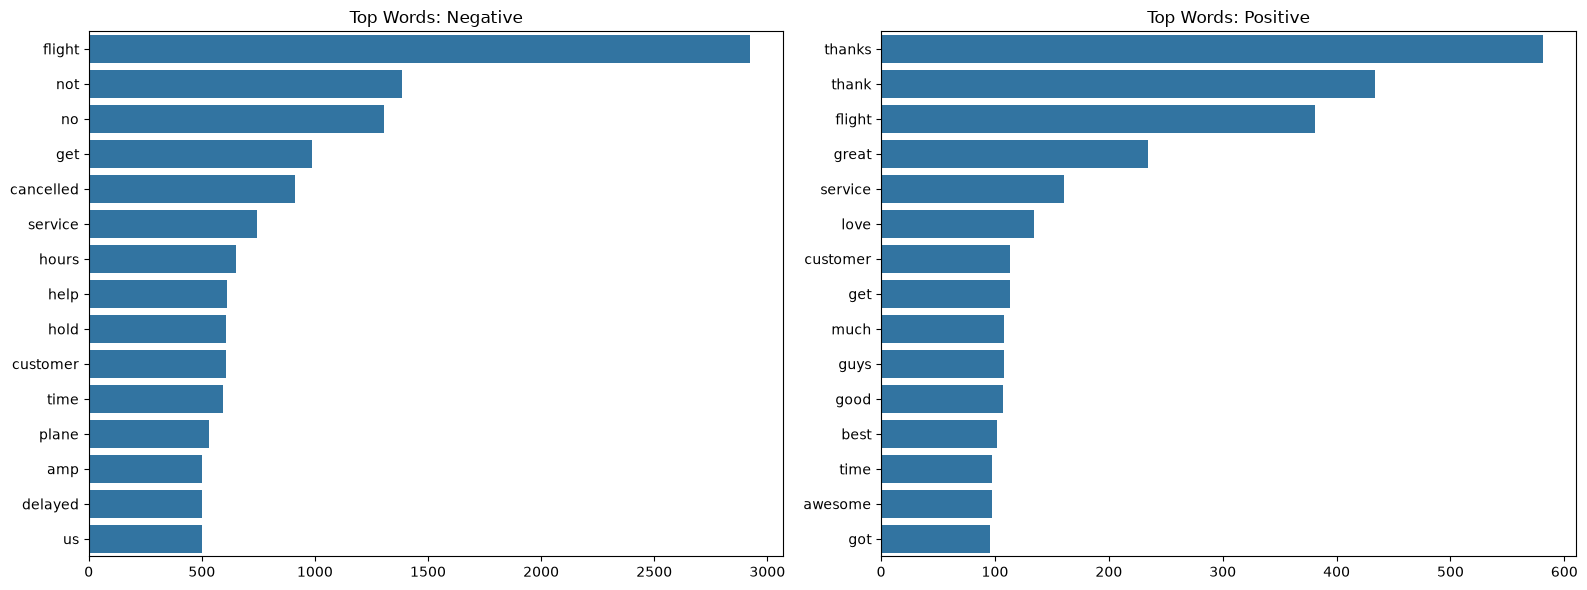

In [78]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 6)
)

for ax, sentiment in zip(
    axes,
    ["negative", "positive"]
):

    tokens = [
        word
        for row in df.loc[
            df["airline_sentiment"] == sentiment,
            "filtered_tokens"
        ]
        for word in row
    ]

    top_words = Counter(tokens).most_common(15)

    words, counts = zip(*top_words)

    sns.barplot(
        x=list(counts),
        y=list(words),
        ax=ax
    )

    ax.set_title(f"Top Words: {sentiment.title()}")

plt.tight_layout()
plt.show()

# Task 3: Different NLP Approaches

## 1. Heuristic Approach

This approach uses manually created positive and negative
word dictionaries.

Advantages:
- Easy to understand.
- No model training required.
- No external API required.

Disadvantages:
- Cannot understand complex sentences.
- May fail with sarcasm.
- Requires manually maintained dictionaries.

## 2. API-based Approach

A ready-made sentiment engine analyses text and returns
a sentiment score.

We will use NLTK VADER.

Advantages:
- No training dataset required.
- Designed for social-media language.

Disadvantages:
- May not understand airline-specific terminology.

## 3. Machine Learning Approach

A machine-learning algorithm learns from labelled
airline tweets.

Advantages:
- Learns patterns from domain-specific data.
- Can improve performance on airline tweets.

Disadvantages:
- Requires labelled training data.
- Needs model evaluation and maintenance.

In [79]:
X = df["clean_text"]

y = df["airline_sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))

Training records: 11561
Testing records: 2891

Training distribution:
airline_sentiment
negative    0.628752
neutral     0.212265
positive    0.158983
Name: proportion, dtype: float64

Testing distribution:
airline_sentiment
negative    0.628848
neutral     0.212037
positive    0.159114
Name: proportion, dtype: float64


In [80]:
positive_words = {
    "good", "great", "excellent", "amazing",
    "awesome", "love", "happy", "best",
    "friendly", "helpful", "thanks", "thank",
    "wonderful", "perfect", "smooth", "quick",
    "comfortable", "appreciate", "enjoy",
    "fantastic", "nice", "easy", "professional",
    "outstanding", "brilliant", "pleased",
    "on time", "delighted", "efficient",
    "polite", "recommend"
}

negative_words = {
    "bad", "worst", "terrible", "awful",
    "delay", "delayed", "cancelled", "cancel",
    "rude", "lost", "missing", "angry",
    "hate", "poor", "late", "problem",
    "issue", "unhappy", "disappointed",
    "frustrated", "horrible", "broken",
    "worse", "waiting", "stuck",
    "unhelpful", "disgusting", "annoying",
    "failure", "unacceptable"
}

print("Positive words:", len(positive_words))
print("Negative words:", len(negative_words))

Positive words: 31
Negative words: 30


In [81]:
def heuristic_sentiment(text):

    tokens = clean_text(text).split()

    positive_score = 0
    negative_score = 0

    negations = {
        "not",
        "no",
        "never"
    }

    for i, word in enumerate(tokens):

        is_negated = any(
            previous in negations
            for previous in tokens[max(0, i-2):i]
        )

        if word in positive_words:

            if is_negated:
                negative_score += 1
            else:
                positive_score += 1

        elif word in negative_words:

            if is_negated:
                positive_score += 1
            else:
                negative_score += 1

    if positive_score > negative_score:
        prediction = "positive"

    elif negative_score > positive_score:
        prediction = "negative"

    else:
        prediction = "neutral"

    return prediction, positive_score, negative_score

In [82]:
examples = [
    "The flight was excellent and amazing",
    "The airline service was terrible",
    "I am not happy with the delay",
    "The flight was good",
    "The service was okay"
]

for sentence in examples:

    prediction, pos, neg = heuristic_sentiment(sentence)

    print("\nTweet:", sentence)
    print("Prediction:", prediction)
    print("Positive score:", pos)
    print("Negative score:", neg)


Tweet: The flight was excellent and amazing
Prediction: positive
Positive score: 2
Negative score: 0

Tweet: The airline service was terrible
Prediction: negative
Positive score: 0
Negative score: 1

Tweet: I am not happy with the delay
Prediction: negative
Positive score: 0
Negative score: 2

Tweet: The flight was good
Prediction: positive
Positive score: 1
Negative score: 0

Tweet: The service was okay
Prediction: neutral
Positive score: 0
Negative score: 0


In [83]:
sia = SentimentIntensityAnalyzer()

def vader_sentiment(text):

    scores = sia.polarity_scores(str(text))

    compound = scores["compound"]

    if compound >= 0.05:
        prediction = "positive"

    elif compound <= -0.05:
        prediction = "negative"

    else:
        prediction = "neutral"

    return prediction, scores

In [84]:
for sentence in examples:

    prediction, scores = vader_sentiment(sentence)

    print("\nTweet:", sentence)
    print("Prediction:", prediction)
    print("Scores:", scores)


Tweet: The flight was excellent and amazing
Prediction: positive
Scores: {'neg': 0.0, 'neu': 0.348, 'pos': 0.652, 'compound': 0.8176}

Tweet: The airline service was terrible
Prediction: negative
Scores: {'neg': 0.437, 'neu': 0.563, 'pos': 0.0, 'compound': -0.4767}

Tweet: I am not happy with the delay
Prediction: negative
Scores: {'neg': 0.57, 'neu': 0.43, 'pos': 0.0, 'compound': -0.6483}

Tweet: The flight was good
Prediction: positive
Scores: {'neg': 0.0, 'neu': 0.508, 'pos': 0.492, 'compound': 0.4404}

Tweet: The service was okay
Prediction: positive
Scores: {'neg': 0.0, 'neu': 0.612, 'pos': 0.388, 'compound': 0.2263}


In [85]:
def evaluate_model(y_true, y_pred, model_name):

    print("\n", "=" * 50)
    print(model_name)
    print("=" * 50)

    print(
        "Accuracy:",
        accuracy_score(y_true, y_pred)
    )

    print(
        "Macro F1:",
        f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )
    )

    print(
        classification_report(
            y_true,
            y_pred,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=["negative", "neutral", "positive"]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["negative", "neutral", "positive"],
        yticklabels=["negative", "neutral", "positive"]
    )

    plt.title(f"{model_name} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


Heuristic Sentiment
Accuracy: 0.5063991698374265
Macro F1: 0.5304492790697742
              precision    recall  f1-score   support

    negative       0.94      0.37      0.53      1818
     neutral       0.29      0.81      0.43       613
    positive       0.61      0.66      0.63       460

    accuracy                           0.51      2891
   macro avg       0.61      0.61      0.53      2891
weighted avg       0.75      0.51      0.52      2891



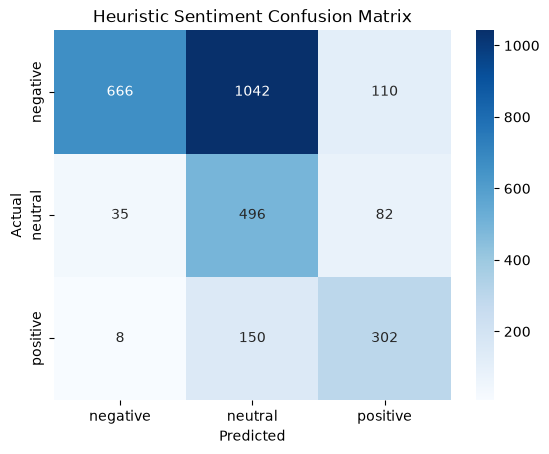

In [86]:
heuristic_predictions = [
    heuristic_sentiment(text)[0]
    for text in X_test
]

evaluate_model(
    y_test,
    heuristic_predictions,
    "Heuristic Sentiment"
)


VADER Sentiment
Accuracy: 0.538913870632999
Macro F1: 0.5046896931375554
              precision    recall  f1-score   support

    negative       0.90      0.50      0.64      1818
     neutral       0.39      0.42      0.40       613
    positive       0.32      0.87      0.47       460

    accuracy                           0.54      2891
   macro avg       0.54      0.59      0.50      2891
weighted avg       0.70      0.54      0.56      2891



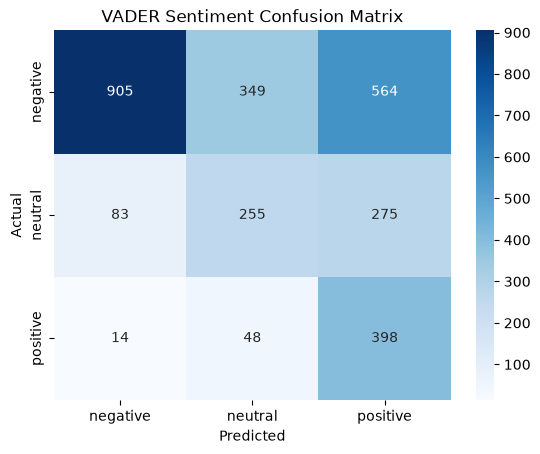

In [87]:
vader_predictions = [
    vader_sentiment(text)[0]
    for text in X_test
]

evaluate_model(
    y_test,
    vader_predictions,
    "VADER Sentiment"
)

In [88]:
approach_results = pd.DataFrame({

    "Approach": [
        "Heuristic",
        "VADER"
    ],

    "Accuracy": [
        accuracy_score(y_test, heuristic_predictions),
        accuracy_score(y_test, vader_predictions)
    ],

    "Macro_F1": [
        f1_score(
            y_test,
            heuristic_predictions,
            average="macro",
            zero_division=0
        ),

        f1_score(
            y_test,
            vader_predictions,
            average="macro",
            zero_division=0
        )
    ]

})

display(approach_results)

,Approach,Accuracy,Macro_F1
0,Heuristic,0.506399,0.530449
1,VADER,0.538914,0.504690


In [89]:
heuristic_errors = pd.DataFrame({
    "Tweet": X_test,
    "Actual": y_test,
    "Predicted": heuristic_predictions
})

heuristic_errors = heuristic_errors[
    heuristic_errors["Actual"] != heuristic_errors["Predicted"]
]

print("Heuristic errors:")
display(heuristic_errors.head(2))

vader_errors = pd.DataFrame({
    "Tweet": X_test,
    "Actual": y_test,
    "Predicted": vader_predictions
})

vader_errors = vader_errors[
    vader_errors["Actual"] != vader_errors["Predicted"]
]

print("VADER errors:")
display(vader_errors.head(2))

Heuristic errors:


,Tweet,Actual,Predicted
13526,finally got a call from aa but it was an autom...,negative,neutral
9733,really a letter that says you will discuss ser...,negative,neutral


VADER errors:


,Tweet,Actual,Predicted
13526,finally got a call from aa but it was an autom...,negative,neutral
9733,really a letter that says you will discuss ser...,negative,positive


# Task 4: Feature Extraction

Machine-learning algorithms cannot directly understand
raw text. Therefore, we convert text into numerical
features.

We will use:

1. Bag of Words
2. TF-IDF
3. Unigrams
4. Bigrams
5. Trigrams

Bag of Words counts word occurrences.
TF-IDF gives importance to words based on their
frequency across documents.
N-Grams capture combinations of consecutive words.

In [92]:
sentences = [
    "the flight was good",
    "the flight was not bad",
    "the airline service was excellent",
    "the airline service was bad"
]

In [93]:
tokenized_sentences = [
    sentence.split()
    for sentence in sentences
]

vocabulary = sorted(
    set(
        word
        for sentence in tokenized_sentences
        for word in sentence
    )
)

bow_manual = []

for sentence in tokenized_sentences:

    counts = Counter(sentence)

    row = [
        counts.get(word, 0)
        for word in vocabulary
    ]

    bow_manual.append(row)

bow_manual_df = pd.DataFrame(
    bow_manual,
    columns=vocabulary
)

display(bow_manual_df)

,airline,bad,excellent,flight,good,not,service,the,was
0,0,0,0,1,1,0,0,1,1
1,0,1,0,1,0,1,0,1,1
2,1,0,1,0,0,0,1,1,1
3,1,1,0,0,0,0,1,1,1


In [94]:
count_vectorizer = CountVectorizer()

bow_matrix = count_vectorizer.fit_transform(sentences)

bow_sklearn_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out()
)

display(bow_sklearn_df)

,airline,bad,excellent,flight,good,not,service,the,was
0,0,0,0,1,1,0,0,1,1
1,0,1,0,1,0,1,0,1,1
2,1,0,1,0,0,0,1,1,1
3,1,1,0,0,0,0,1,1,1


In [95]:
print(
    "Both methods match:",
    np.array_equal(
        bow_manual_df.values,
        bow_sklearn_df.values
    )
)

Both methods match: True


In [96]:
N = len(sentences)

tfidf_manual = []

for sentence in tokenized_sentences:

    counts = Counter(sentence)

    row = []

    for word in vocabulary:

        tf = counts.get(word, 0)

        document_frequency = sum(
            1
            for doc in tokenized_sentences
            if word in doc
        )

        idf = np.log(
            N / document_frequency
        ) + 1

        row.append(tf * idf)

    tfidf_manual.append(row)

tfidf_manual_df = pd.DataFrame(
    tfidf_manual,
    columns=vocabulary
)

display(tfidf_manual_df.round(3))

,airline,bad,excellent,flight,good,not,service,the,was
0,0.000,0.000,0.000,1.693,2.386,0.000,0.000,1.0,1.0
1,0.000,1.693,0.000,1.693,0.000,2.386,0.000,1.0,1.0
2,1.693,0.000,2.386,0.000,0.000,0.000,1.693,1.0,1.0
3,1.693,1.693,0.000,0.000,0.000,0.000,1.693,1.0,1.0


In [97]:
manual_tfidf_vectorizer = TfidfVectorizer(
    smooth_idf=False,
    norm=None
)

tfidf_matrix_manual_check = (
    manual_tfidf_vectorizer.fit_transform(sentences)
)

tfidf_sklearn_df = pd.DataFrame(
    tfidf_matrix_manual_check.toarray(),
    columns=manual_tfidf_vectorizer.get_feature_names_out()
)

display(tfidf_sklearn_df.round(3))

,airline,bad,excellent,flight,good,not,service,the,was
0,0.000,0.000,0.000,1.693,2.386,0.000,0.000,1.0,1.0
1,0.000,1.693,0.000,1.693,0.000,2.386,0.000,1.0,1.0
2,1.693,0.000,2.386,0.000,0.000,0.000,1.693,1.0,1.0
3,1.693,1.693,0.000,0.000,0.000,0.000,1.693,1.0,1.0


In [98]:
print(
    "Manual and sklearn TF-IDF match:",
    np.allclose(
        tfidf_manual_df.values,
        tfidf_sklearn_df.values
    )
)

Manual and sklearn TF-IDF match: True


In [99]:
default_tfidf = TfidfVectorizer()

default_matrix = default_tfidf.fit_transform(sentences)

display(
    pd.DataFrame(
        default_matrix.toarray(),
        columns=default_tfidf.get_feature_names_out()
    ).round(3)
)

,airline,bad,excellent,flight,good,not,service,the,was
0,0.000,0.000,0.000,0.536,0.679,0.000,0.000,0.355,0.355
1,0.000,0.472,0.000,0.472,0.000,0.599,0.000,0.313,0.313
2,0.472,0.000,0.599,0.000,0.000,0.000,0.472,0.313,0.313
3,0.508,0.508,0.000,0.000,0.000,0.000,0.508,0.336,0.336


In [100]:
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=5000
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)

X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

print("Vocabulary size:", len(tfidf_vectorizer.vocabulary_))

print("Training non-zero entries:", X_train_tfidf.nnz)

total_elements = (
    X_train_tfidf.shape[0] *
    X_train_tfidf.shape[1]
)

sparsity = (
    1 - X_train_tfidf.nnz / total_elements
) * 100

print("Sparsity:", round(sparsity, 2), "%")

Training shape: (11561, 5000)
Testing shape: (2891, 5000)
Vocabulary size: 5000
Training non-zero entries: 215888
Sparsity: 99.63 %


In [101]:
for min_df in [1, 2, 3]:

    vectorizer = TfidfVectorizer(
        min_df=min_df,
        max_features=5000
    )

    matrix = vectorizer.fit_transform(X_train)

    print(
        "min_df:",
        min_df,
        "| Vocabulary:",
        len(vectorizer.vocabulary_)
    )

min_df: 1 | Vocabulary: 5000
min_df: 2 | Vocabulary: 4945
min_df: 3 | Vocabulary: 3627


In [102]:
ngram_results = []

for ngram in [
    (1, 1),
    (1, 2),
    (1, 3)
]:

    vectorizer = TfidfVectorizer(
        ngram_range=ngram,
        min_df=2,
        max_features=10000
    )

    matrix = vectorizer.fit_transform(X_train)

    ngram_results.append({
        "N-Gram": str(ngram),
        "Vocabulary Size": len(vectorizer.vocabulary_),
        "Memory (Bytes)": matrix.data.nbytes
    })

ngram_results_df = pd.DataFrame(ngram_results)

display(ngram_results_df)

,N-Gram,Vocabulary Size,Memory (Bytes)
0,"(1, 1)",4945,1295664
1,"(1, 2)",10000,1914760
2,"(1, 3)",10000,1989440


In [103]:
bigram_vectorizer = TfidfVectorizer(
    ngram_range=(2, 2),
    min_df=2,
    max_features=10000
)

X_train_bigram = bigram_vectorizer.fit_transform(X_train)

bigram_names = bigram_vectorizer.get_feature_names_out()

for sentiment in ["negative", "positive"]:

    sentiment_indices = (
        y_train.values == sentiment
    )

    average_weights = np.asarray(
        X_train_bigram[sentiment_indices].mean(axis=0)
    ).ravel()

    top_indices = np.argsort(
        average_weights
    )[::-1][:15]

    print("\n", sentiment.upper())

    display(
        pd.DataFrame({
            "Bigram": bigram_names[top_indices],
            "Average TF-IDF": average_weights[top_indices]
        })
    )


 NEGATIVE


,Bigram,Average TF-IDF
0,on hold,0.010934
1,customer service,0.010080
2,cancelled flightled,0.009157
3,on the,0.008903
4,my flight,0.007767
5,to get,0.007500
6,to be,0.006328
7,trying to,0.005910
8,hold for,0.005857
9,an hour,0.005595



 POSITIVE


,Bigram,Average TF-IDF
0,thank you,0.066404
1,thanks for,0.026427
2,for the,0.021754
3,you for,0.014974
4,you guys,0.011284
5,so much,0.010286
6,customer service,0.009783
7,the best,0.009093
8,for your,0.007973
9,in the,0.006724


In [104]:
feature_experiment = []

for max_features in [
    1000,
    3000,
    5000,
    10000
]:

    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=max_features
    )

    matrix = vectorizer.fit_transform(X_train)

    feature_experiment.append({
        "Max Features": max_features,
        "Actual Vocabulary": len(vectorizer.vocabulary_),
        "Memory Bytes": matrix.data.nbytes
    })

feature_experiment_df = pd.DataFrame(
    feature_experiment
)

display(feature_experiment_df)

,Max Features,Actual Vocabulary,Memory Bytes
0,1000,1000,1291064
1,3000,3000,1587768
2,5000,5000,1727104
3,10000,10000,1914760


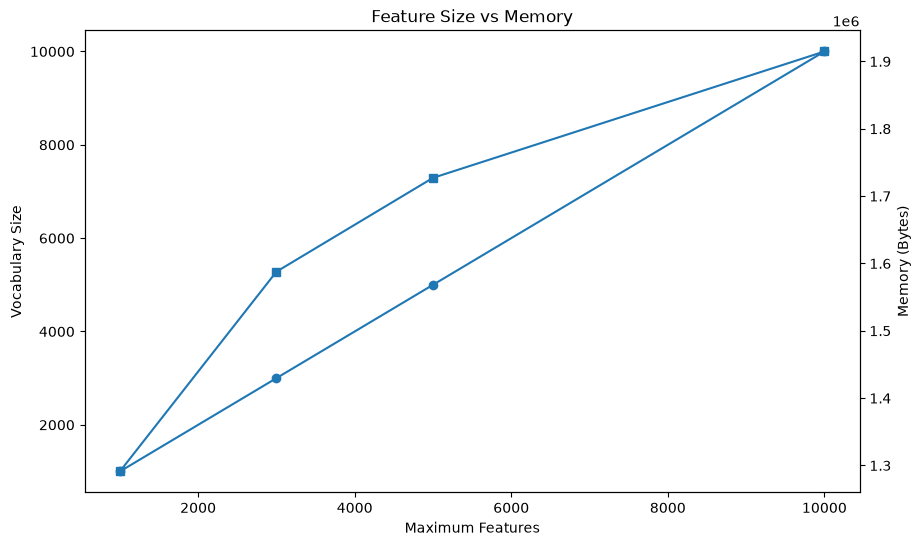

In [105]:
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(
    feature_experiment_df["Max Features"],
    feature_experiment_df["Actual Vocabulary"],
    marker="o",
    label="Vocabulary"
)

ax1.set_xlabel("Maximum Features")
ax1.set_ylabel("Vocabulary Size")

ax2 = ax1.twinx()

ax2.plot(
    feature_experiment_df["Max Features"],
    feature_experiment_df["Memory Bytes"],
    marker="s",
    label="Memory"
)

ax2.set_ylabel("Memory (Bytes)")

plt.title("Feature Size vs Memory")
plt.show()

# Task 5: Word Embeddings

Bag of Words and TF-IDF treat every word as an
independent feature.

Word2Vec converts words into dense numerical vectors.

Words that appear in similar contexts can have similar
representations.

The basic idea is:

"A word is known by the company it keeps."

## CBoW

Continuous Bag of Words predicts the centre word
using surrounding context words.

## Skip-gram

Skip-gram predicts surrounding context words
using the centre word.

In [106]:
train_tokens = [
    text.split()
    for text in X_train
]

test_tokens = [
    text.split()
    for text in X_test
]

print("Training documents:", len(train_tokens))
print("Testing documents:", len(test_tokens))

Training documents: 11561
Testing documents: 2891


In [107]:
start_time = time.time()

cbow_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=3,
    sg=0,
    epochs=20,
    seed=42,
    workers=1
)

cbow_time = time.time() - start_time

print("CBoW vocabulary:", len(cbow_model.wv))
print("CBoW vector shape:", cbow_model.wv.vectors.shape)
print("CBoW training time:", round(cbow_time, 2))

CBoW vocabulary: 3681
CBoW vector shape: (3681, 100)
CBoW training time: 3.76


In [108]:
start_time = time.time()

skipgram_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    epochs=20,
    seed=42,
    workers=1
)

skipgram_time = time.time() - start_time

print("Skip-gram vocabulary:", len(skipgram_model.wv))
print("Skip-gram vector shape:", skipgram_model.wv.vectors.shape)
print("Skip-gram training time:", round(skipgram_time, 2))

Skip-gram vocabulary: 3681
Skip-gram vector shape: (3681, 100)
Skip-gram training time: 10.97


In [109]:
query_words = [
    "delayed",
    "flight",
    "thanks",
    "rude",
    "luggage",
    "great"
]

similarity_results = []

for word in query_words:

    for model_name, model in [
        ("CBoW", cbow_model),
        ("Skip-gram", skipgram_model)
    ]:

        if word in model.wv:

            similar = model.wv.most_similar(
                word,
                topn=5
            )

            similarity_results.append({
                "Model": model_name,
                "Word": word,
                "Similar Words": similar
            })

display(pd.DataFrame(similarity_results))

,Model,Word,Similar Words
0,CBoW,delayed,"[(late, 0.6780285239219666), (missed, 0.644935..."
1,Skip-gram,delayed,"[(inbound, 0.600432276725769), (thurs, 0.57999..."
2,CBoW,flight,"[(flt, 0.6880010962486267), (connection, 0.606..."
3,Skip-gram,flight,"[(tire, 0.6583988666534424), (flts, 0.65636223..."
4,CBoW,thanks,"[(thx, 0.7747949957847595), (thank, 0.70149850..."
5,Skip-gram,thanks,"[(thank, 0.5609260201454163), (shoutout, 0.549..."
6,CBoW,rude,"[(helpful, 0.7860846519470215), (unhelpful, 0...."
7,Skip-gram,rude,"[(unprofessional, 0.7122302055358887), (fabulo..."
8,CBoW,luggage,"[(bag, 0.8324414491653442), (bags, 0.797776341..."
9,Skip-gram,luggage,"[(bags, 0.6246160864830017), (wallet, 0.605141..."


In [110]:
word_pairs = [
    ("delayed", "late"),
    ("good", "great"),
    ("flight", "banana")
]

for word1, word2 in word_pairs:

    if (
        word1 in skipgram_model.wv and
        word2 in skipgram_model.wv
    ):

        score = skipgram_model.wv.similarity(
            word1,
            word2
        )

        print(
            word1,
            "and",
            word2,
            ":",
            round(score, 4)
        )

    else:

        print(
            word1,
            "or",
            word2,
            "not present in vocabulary"
        )

delayed and late : 0.5286
good and great : 0.432
flight or banana not present in vocabulary


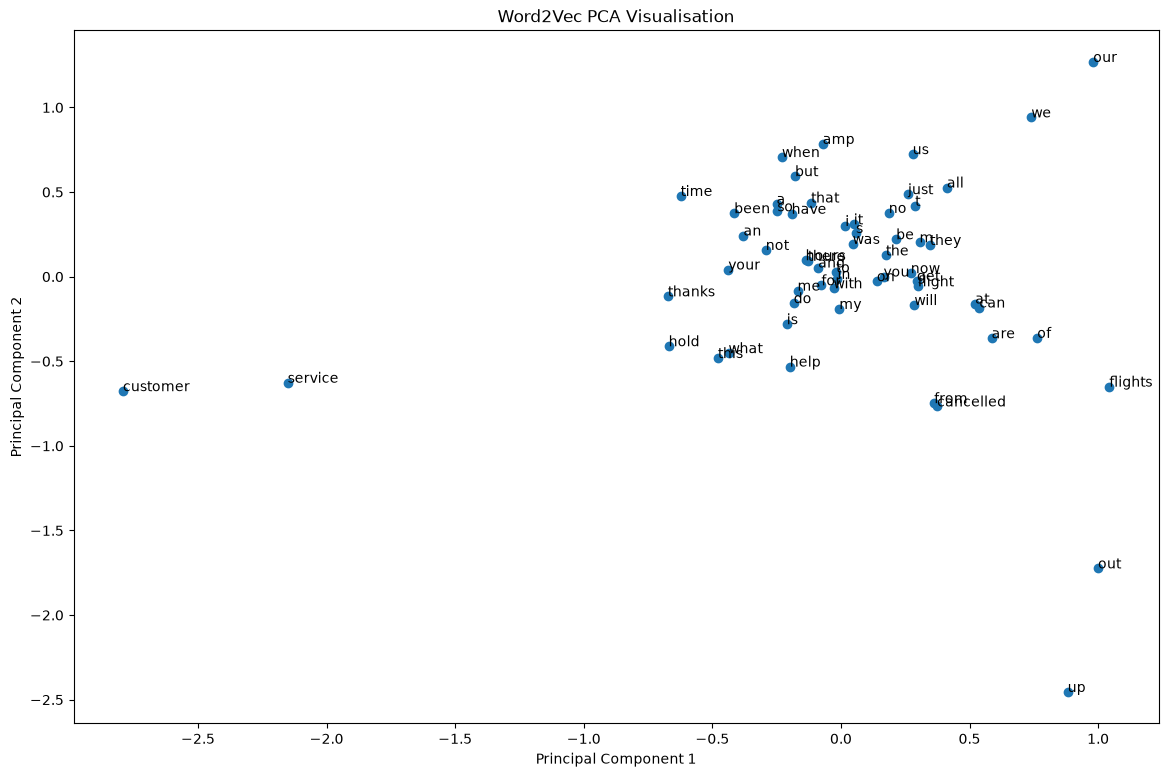

In [111]:
most_common_words = Counter(
    word
    for sentence in train_tokens
    for word in sentence
).most_common(60)

selected_words = [
    word
    for word, count in most_common_words
    if word in skipgram_model.wv
]

vectors = np.array([
    skipgram_model.wv[word]
    for word in selected_words
])

pca = PCA(n_components=2)

reduced_vectors = pca.fit_transform(vectors)

plt.figure(figsize=(14, 9))

plt.scatter(
    reduced_vectors[:, 0],
    reduced_vectors[:, 1]
)

for i, word in enumerate(selected_words):

    plt.annotate(
        word,
        (
            reduced_vectors[i, 0],
            reduced_vectors[i, 1]
        )
    )

plt.title("Word2Vec PCA Visualisation")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [112]:
def doc_vector(tokens, model):

    vectors = [
        model.wv[word]
        for word in tokens
        if word in model.wv
    ]

    if len(vectors) == 0:

        return np.zeros(
            model.vector_size
        )

    return np.mean(
        vectors,
        axis=0
    )

In [113]:
X_train_w2v = np.array([
    doc_vector(tokens, skipgram_model)
    for tokens in train_tokens
])

X_test_w2v = np.array([
    doc_vector(tokens, skipgram_model)
    for tokens in test_tokens
])

print("Training shape:", X_train_w2v.shape)
print("Testing shape:", X_test_w2v.shape)

Training shape: (11561, 100)
Testing shape: (2891, 100)


## Word2Vec Limitations

The airline dataset is relatively small compared with
large general-purpose language corpora.

Therefore, some word vectors may be noisy.

Averaging word vectors also loses word order and some
sentence-level context.

# Task 6: Text Classification

Text classification assigns a category or label to
a complete document.

In this project, the input is an airline tweet and
the output is one of three sentiment labels:

- Negative
- Neutral
- Positive

The classification pipeline is:

Raw Text → Cleaning → Feature Extraction →
Classifier → Prediction → Evaluation

A Scikit-learn Pipeline combines feature extraction
and classification. It also helps prevent data leakage
during training and cross-validation.


TF-IDF + Logistic Regression
Accuracy: 0.7820823244552058
Macro F1: 0.7293302831367656
              precision    recall  f1-score   support

    negative       0.88      0.84      0.86      1818
     neutral       0.58      0.63      0.61       613
    positive       0.71      0.73      0.72       460

    accuracy                           0.78      2891
   macro avg       0.72      0.74      0.73      2891
weighted avg       0.79      0.78      0.78      2891



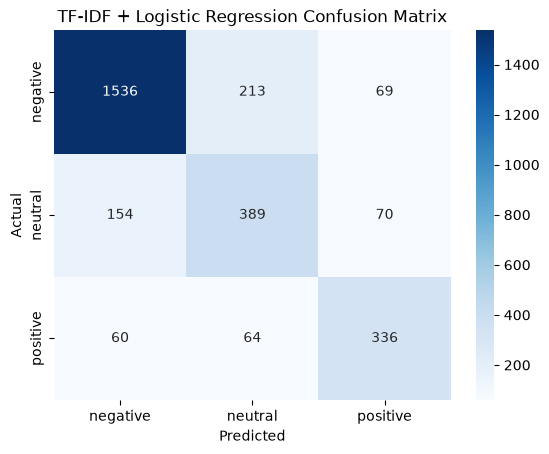

Training time: 1.9 seconds


In [114]:
baseline_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )
    ),

    (
        "clf",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

start_time = time.time()

baseline_pipeline.fit(
    X_train,
    y_train
)

baseline_time = time.time() - start_time

baseline_predictions = baseline_pipeline.predict(
    X_test
)

evaluate_model(
    y_test,
    baseline_predictions,
    "TF-IDF + Logistic Regression"
)

print("Training time:", round(baseline_time, 2), "seconds")

In [115]:
models = {

    "BoW + Naive Bayes": Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", MultinomialNB())
    ]),

    "BoW + Logistic Regression": Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "TF-IDF Unigram + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(
            ngram_range=(1, 1),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "TF-IDF Bigram + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Word2Vec + Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
}

In [116]:
models = {

    "BoW + Naive Bayes": Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", MultinomialNB())
    ]),

    "BoW + Logistic Regression": Pipeline([
        ("vectorizer", CountVectorizer()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "TF-IDF Unigram + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(
            ngram_range=(1, 1),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "TF-IDF Bigram + Logistic Regression": Pipeline([
        ("vectorizer", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Word2Vec + Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    )
}

In [117]:
ml_results = []
trained_models = {}

for name, model in models.items():

    start_time = time.time()

    if name == "Word2Vec + Logistic Regression":

        model.fit(
            X_train_w2v,
            y_train
        )

        predictions = model.predict(
            X_test_w2v
        )

    else:

        model.fit(
            X_train,
            y_train
        )

        predictions = model.predict(
            X_test
        )

    training_time = time.time() - start_time

    report = classification_report(
        y_test,
        predictions,
        output_dict=True,
        zero_division=0
    )

    ml_results.append({

        "Features + Classifier": name,

        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),

        "Macro-F1": f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Negative Precision": report["negative"]["precision"],

        "Positive Recall": report["positive"]["recall"],

        "Training Time": training_time
    })

    trained_models[name] = model

ml_results_df = pd.DataFrame(ml_results)

display(
    ml_results_df.sort_values(
        "Macro-F1",
        ascending=False
    )
)

,Features + Classifier,Accuracy,Macro-F1,Negative Precision,Positive Recall,Training Time
3,TF-IDF Bigram + Logistic Regression,0.782082,0.729330,0.877714,0.730435,1.352904
2,TF-IDF Unigram + Logistic Regression,0.762712,0.714826,0.889227,0.719565,0.595778
1,BoW + Logistic Regression,0.759945,0.711760,0.885176,0.726087,0.948219
4,Word2Vec + Logistic Regression,0.714286,0.662701,0.861529,0.691304,0.293994
0,BoW + Naive Bayes,0.760636,0.658381,0.769472,0.541304,0.364902


In [118]:
best_model_name = ml_results_df.loc[
    ml_results_df["Macro-F1"].idxmax(),
    "Features + Classifier"
]

best_ml_model = trained_models[best_model_name]

print("Best ML model:", best_model_name)

Best ML model: TF-IDF Bigram + Logistic Regression



Word2Vec + Logistic Regression
Accuracy: 0.7142857142857143
Macro F1: 0.6627006470699836
              precision    recall  f1-score   support

    negative       0.86      0.76      0.81      1818
     neutral       0.49      0.61      0.54       613
    positive       0.60      0.69      0.64       460

    accuracy                           0.71      2891
   macro avg       0.65      0.68      0.66      2891
weighted avg       0.74      0.71      0.72      2891



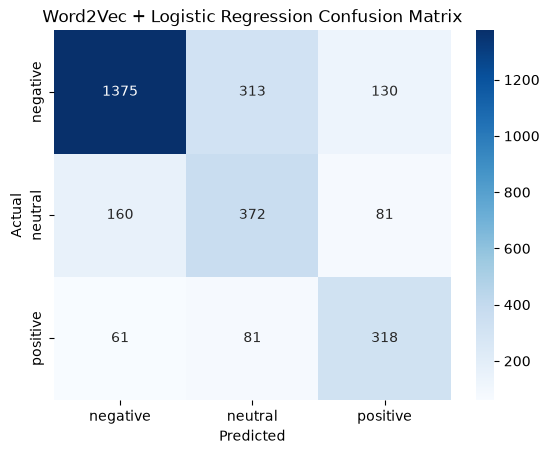

In [119]:
word2vec_predictions = trained_models[
    "Word2Vec + Logistic Regression"
].predict(X_test_w2v)

evaluate_model(
    y_test,
    word2vec_predictions,
    "Word2Vec + Logistic Regression"
)

In [120]:
heuristic_result = {
    "Features + Classifier": "Heuristic",
    "Accuracy": accuracy_score(
        y_test,
        heuristic_predictions
    ),
    "Macro-F1": f1_score(
        y_test,
        heuristic_predictions,
        average="macro"
    )
}

vader_result = {
    "Features + Classifier": "VADER",
    "Accuracy": accuracy_score(
        y_test,
        vader_predictions
    ),
    "Macro-F1": f1_score(
        y_test,
        vader_predictions,
        average="macro"
    )
}

comparison_results = pd.concat([
    pd.DataFrame([heuristic_result, vader_result]),
    ml_results_df
], ignore_index=True)

display(
    comparison_results.sort_values(
        "Macro-F1",
        ascending=False
    )
)

,Features + Classifier,Accuracy,Macro-F1,Negative Precision,Positive Recall,Training Time
5,TF-IDF Bigram + Logistic Regression,0.782082,0.729330,0.877714,0.730435,1.352904
4,TF-IDF Unigram + Logistic Regression,0.762712,0.714826,0.889227,0.719565,0.595778
3,BoW + Logistic Regression,0.759945,0.711760,0.885176,0.726087,0.948219
6,Word2Vec + Logistic Regression,0.714286,0.662701,0.861529,0.691304,0.293994
2,BoW + Naive Bayes,0.760636,0.658381,0.769472,0.541304,0.364902
0,Heuristic,0.506399,0.530449,NaN,NaN,NaN
1,VADER,0.538914,0.504690,NaN,NaN,NaN


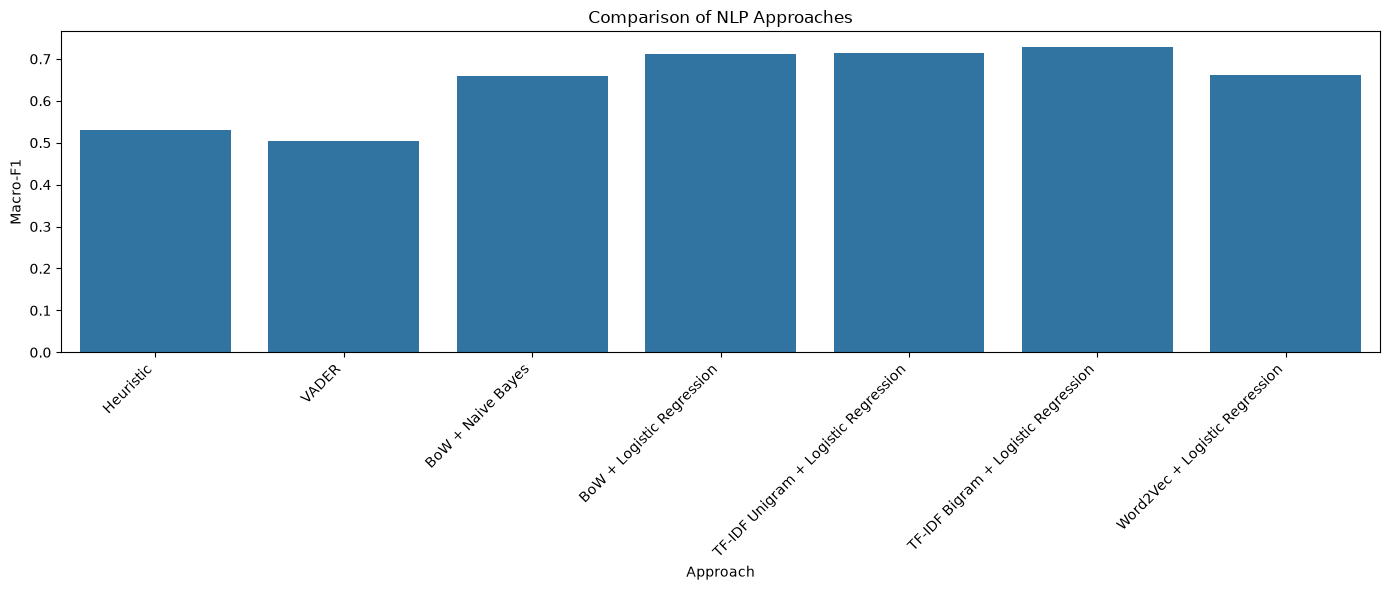

In [121]:
plt.figure(figsize=(14, 6))

sns.barplot(
    data=comparison_results,
    x="Features + Classifier",
    y="Macro-F1"
)

plt.title("Comparison of NLP Approaches")
plt.xlabel("Approach")
plt.ylabel("Macro-F1")

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()
plt.show()

In [122]:
best_cv_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    best_cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1
)

print("Cross-validation scores:", cv_scores)

print("Mean Macro-F1:", cv_scores.mean())

print("Standard Deviation:", cv_scores.std())

Cross-validation scores: [0.72596219 0.74034602 0.73618288 0.74801858 0.73471538]
Mean Macro-F1: 0.7370450079651863
Standard Deviation: 0.007215472688828951


In [123]:
best_cv_pipeline.fit(
    X_train,
    y_train
)

cv_test_predictions = best_cv_pipeline.predict(
    X_test
)

test_macro_f1 = f1_score(
    y_test,
    cv_test_predictions,
    average="macro"
)

print("CV Mean:", cv_scores.mean())
print("Test Macro-F1:", test_macro_f1)

print(
    "Difference:",
    abs(cv_scores.mean() - test_macro_f1)
)

CV Mean: 0.7370450079651863
Test Macro-F1: 0.7293302831367656
Difference: 0.007714724828420727


In [124]:
error_predictions = best_cv_pipeline.predict(
    X_test
)

error_probabilities = best_cv_pipeline.predict_proba(
    X_test
)

errors_df = pd.DataFrame({

    "Original Tweet": df.loc[
        X_test.index,
        "text"
    ].values,

    "True Label": y_test.values,

    "Predicted Label": error_predictions,

    "Probability": error_probabilities.max(axis=1)

}, index=X_test.index)

errors_df = errors_df[
    errors_df["True Label"] != errors_df["Predicted Label"]
]

display(errors_df.head(8))

,Original Tweet,True Label,Predicted Label,Probability
5509,@SouthwestAir OMG OMG OMG !!! I JUST DID!!,neutral,positive,0.597818
8557,@JetBlue insensitive? #FoodAllergies are life-...,negative,neutral,0.518129
1032,@united Not a happy flyer. UA flight 1161 fro...,negative,neutral,0.458404
11305,@USAirways the Late Flightr flight to Charlest...,negative,neutral,0.461087
5510,@SouthwestAir @JulGood1 she was traveling with...,negative,positive,0.396650
9125,"@USAirways Instead of fair treatment, I got a...",negative,neutral,0.541004
12276,@AmericanAir that's what is on my ticket and m...,neutral,negative,0.550836
10388,@USAirways FINALLY leaving 4 home from NC. Wil...,negative,neutral,0.404224


## Error Analysis

Common reasons for incorrect predictions:

1. Sarcasm – The literal words may not represent
   the actual sentiment.
2. Negation – A sentence can change meaning
   when negation is used.
3. Very short tweets – There may be insufficient
   information for classification.
4. Mixed sentiment – A tweet may contain both
   positive and negative opinions.

Possible improvements:

- Experiment with trigram features.
- Adjust min_df and max_features.

In [125]:
# Use the selected model from the comparison.
if best_model_name == "Word2Vec + Logistic Regression":

    final_pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    # A deployable Word2Vec model needs its Word2Vec
    # preprocessing and feature conversion too.
    # For the Streamlit app, use a text-based pipeline.

else:

    final_pipeline = trained_models[best_model_name]

final_pipeline.fit(
    X_train,
    y_train
)

joblib.dump(
    final_pipeline,
    "sentiment_model.joblib"
)

print("Final model saved successfully!")

Final model saved successfully!


In [126]:
loaded_model = joblib.load(
    "sentiment_model.joblib"
)

print("Model loaded successfully!")

print(
    "Scikit-learn version:",
    sklearn.__version__
)

Model loaded successfully!
Scikit-learn version: 1.9.1


In [127]:
new_tweets = [
    "The flight service was excellent and amazing",
    "My flight was delayed and the service was terrible",
    "The flight was okay"
]

for tweet in new_tweets:

    cleaned = clean_text(tweet)

    prediction = loaded_model.predict([
        cleaned
    ])[0]

    print("\nOriginal:", tweet)
    print("Cleaned:", cleaned)
    print("Prediction:", prediction)


Original: The flight service was excellent and amazing
Cleaned: the flight service was excellent and amazing
Prediction: positive

Original: My flight was delayed and the service was terrible
Cleaned: my flight was delayed and the service was terrible
Prediction: negative

Original: The flight was okay
Cleaned: the flight was okay
Prediction: negative


# Task 7: Part-of-Speech Tagging

POS tagging identifies the grammatical role of
each word in a sentence.

Common Penn Treebank tags:

| Tag | Meaning |
|---|---|
| NN | Noun |
| VB | Verb |
| JJ | Adjective |
| RB | Adverb |
| PRP | Pronoun |
| IN | Preposition |

POS tagging is useful for information extraction,
grammar checking, disambiguation and improving
text classification features.

## How POS Tagging Works

1. Rule-based tagging uses dictionaries and
   predefined grammatical rules.
2. Statistical tagging learns patterns from
   previously tagged text.
3. Context helps determine the correct tag.

NLTK pos_tag uses a trained averaged-perceptron
tagger.

The word "book" can be a noun or a verb:

- I read a book. (Noun)
- I will book a flight. (Verb)

In [128]:
ambiguity_sentences = [
    "I read a book.",
    "I will book a flight.",
    "The park is beautiful.",
    "Please park the car."
]

for sentence in ambiguity_sentences:

    tokens = word_tokenize(sentence)

    tags = nltk.pos_tag(tokens)

    print("\nSentence:", sentence)
    print(tags)


Sentence: I read a book.
[('I', 'PRP'), ('read', 'VBP'), ('a', 'DT'), ('book', 'NN'), ('.', '.')]

Sentence: I will book a flight.
[('I', 'PRP'), ('will', 'MD'), ('book', 'NN'), ('a', 'DT'), ('flight', 'NN'), ('.', '.')]

Sentence: The park is beautiful.
[('The', 'DT'), ('park', 'NN'), ('is', 'VBZ'), ('beautiful', 'JJ'), ('.', '.')]

Sentence: Please park the car.
[('Please', 'NNP'), ('park', 'VB'), ('the', 'DT'), ('car', 'NN'), ('.', '.')]


In [129]:
sample_tweets = df["clean_text"].head(5)

for tweet in sample_tweets:

    tokens = word_tokenize(tweet)

    tags = nltk.pos_tag(tokens)

    print("\nTweet:", tweet)
    print("POS Tags:", tags)


Tweet: what said
POS Tags: [('what', 'WP'), ('said', 'VBD')]

Tweet: plus you ve added commercials to the experience tacky
POS Tags: [('plus', 'CC'), ('you', 'PRP'), ('ve', 'VBP'), ('added', 'JJ'), ('commercials', 'NNS'), ('to', 'TO'), ('the', 'DT'), ('experience', 'NN'), ('tacky', 'NN')]

Tweet: i didn t today must mean i need to take another trip
POS Tags: [('i', 'NN'), ('didn', 'VBP'), ('t', 'NN'), ('today', 'NN'), ('must', 'MD'), ('mean', 'VB'), ('i', 'NNS'), ('need', 'VBP'), ('to', 'TO'), ('take', 'VB'), ('another', 'DT'), ('trip', 'NN')]

Tweet: it s really aggressive to blast obnoxious entertainment in your guests faces amp they have little recourse
POS Tags: [('it', 'PRP'), ('s', 'VBZ'), ('really', 'RB'), ('aggressive', 'JJ'), ('to', 'TO'), ('blast', 'VB'), ('obnoxious', 'JJ'), ('entertainment', 'NN'), ('in', 'IN'), ('your', 'PRP$'), ('guests', 'NNS'), ('faces', 'VBZ'), ('amp', 'IN'), ('they', 'PRP'), ('have', 'VBP'), ('little', 'JJ'), ('recourse', 'NN')]

Tweet: and it s a re

In [130]:
pos_data = []

for tweet in sample_tweets:

    tokens = word_tokenize(tweet)

    tags = nltk.pos_tag(tokens)

    for word, tag in tags:

        pos_data.append({
            "Tweet": tweet,
            "Word": word,
            "POS Tag": tag
        })

pos_df = pd.DataFrame(pos_data)

display(pos_df)

,Tweet,Word,POS Tag
0,what said,what,WP
1,what said,said,VBD
2,plus you ve added commercials to the experienc...,plus,CC
3,plus you ve added commercials to the experienc...,you,PRP
4,plus you ve added commercials to the experienc...,ve,VBP
5,plus you ve added commercials to the experienc...,added,JJ
6,plus you ve added commercials to the experienc...,commercials,NNS
7,plus you ve added commercials to the experienc...,to,TO
8,plus you ve added commercials to the experienc...,the,DT
9,plus you ve added commercials to the experienc...,experience,NN


In [131]:
pos_sample = pd.DataFrame({
    "text": X_train.iloc[:2000].values,
    "sentiment": y_train.iloc[:2000].values
})

pos_records = []

for _, row in pos_sample.iterrows():

    tokens = word_tokenize(row["text"])

    tagged = nltk.pos_tag(tokens)

    total = max(len(tagged), 1)

    counts = {
        "Adjectives": 0,
        "Adverbs": 0,
        "Verbs": 0,
        "Nouns": 0
    }

    for word, tag in tagged:

        if tag.startswith("JJ"):
            counts["Adjectives"] += 1

        elif tag.startswith("RB"):
            counts["Adverbs"] += 1

        elif tag.startswith("VB"):
            counts["Verbs"] += 1

        elif tag.startswith("NN"):
            counts["Nouns"] += 1

    for category, count in counts.items():

        pos_records.append({
            "Sentiment": row["sentiment"],
            "POS Category": category,
            "Proportion": count / total
        })

pos_distribution = pd.DataFrame(
    pos_records
)

pos_summary = pos_distribution.groupby(
    ["Sentiment", "POS Category"]
)["Proportion"].mean().reset_index()

display(pos_summary)

,Sentiment,POS Category,Proportion
0,negative,Adjectives,0.084343
1,negative,Adverbs,0.065231
2,negative,Nouns,0.288668
3,negative,Verbs,0.220398
4,neutral,Adjectives,0.080373
5,neutral,Adverbs,0.040421
6,neutral,Nouns,0.334031
7,neutral,Verbs,0.212599
8,positive,Adjectives,0.107701
9,positive,Adverbs,0.068708


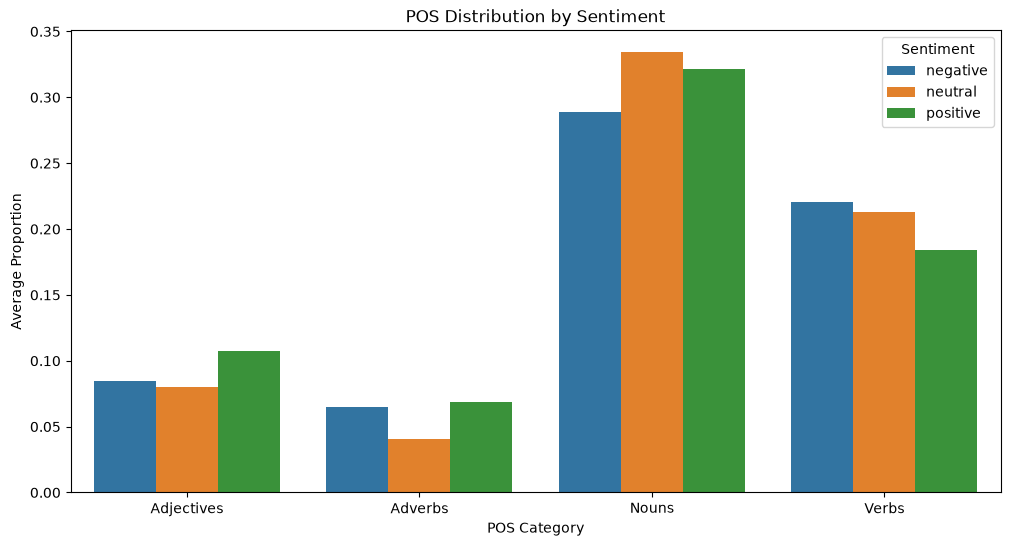

In [132]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=pos_summary,
    x="POS Category",
    y="Proportion",
    hue="Sentiment"
)

plt.title("POS Distribution by Sentiment")
plt.xlabel("POS Category")
plt.ylabel("Average Proportion")

plt.show()

In [133]:
adjective_words = {
    "negative": [],
    "positive": []
}

for sentiment in adjective_words:

    tweets = X_train[
        y_train == sentiment
    ].iloc[:2000]

    for tweet in tweets:

        tagged = nltk.pos_tag(
            word_tokenize(tweet)
        )

        for word, tag in tagged:

            if tag.startswith("JJ"):

                adjective_words[sentiment].append(word)

    print("\n", sentiment.upper())

    display(
        pd.DataFrame(
            Counter(
                adjective_words[sentiment]
            ).most_common(10),
            columns=["Adjective", "Frequency"]
        )
    )


 NEGATIVE


,Adjective,Frequency
0,i,208
1,t,79
2,late,78
3,worst,49
4,flightled,49
5,last,45
6,more,43
7,united,41
8,due,36
9,next,35



 POSITIVE


,Adjective,Frequency
0,great,191
1,i,127
2,good,78
3,awesome,74
4,best,71
5,much,47
6,new,41
7,nice,33
8,first,31
9,helpful,30


In [134]:
def pos_filter_text(text):

    tokens = word_tokenize(text)

    tagged = nltk.pos_tag(tokens)

    selected_words = []

    for word, tag in tagged:

        if (
            tag.startswith("JJ")
            or tag.startswith("RB")
            or tag.startswith("VB")
            or word in negation_words
        ):

            selected_words.append(word)

    return " ".join(selected_words)

In [135]:
X_train_pos = X_train.apply(
    pos_filter_text
)

X_test_pos = X_test.apply(
    pos_filter_text
)

print(X_train_pos.head())

8706                            no did said was delicious
8500                              ath do coordinate other
7860                                    wow amazing great
11044                                     delayed further
12398    were stuck supposed be going okc s w much longer
Name: clean_text, dtype: str


In [136]:
pos_pipeline = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )

])

pos_pipeline.fit(
    X_train_pos,
    y_train
)

pos_predictions = pos_pipeline.predict(
    X_test_pos
)

pos_f1 = f1_score(
    y_test,
    pos_predictions,
    average="macro"
)

full_text_f1 = f1_score(
    y_test,
    best_cv_pipeline.predict(X_test),
    average="macro"
)

print("Full-text Macro-F1:", full_text_f1)

print("POS-filtered Macro-F1:", pos_f1)

Full-text Macro-F1: 0.7293302831367656
POS-filtered Macro-F1: 0.6333067022087334


,Model,Macro-F1
0,Full Text TF-IDF,0.729330
1,POS Filtered TF-IDF,0.633307


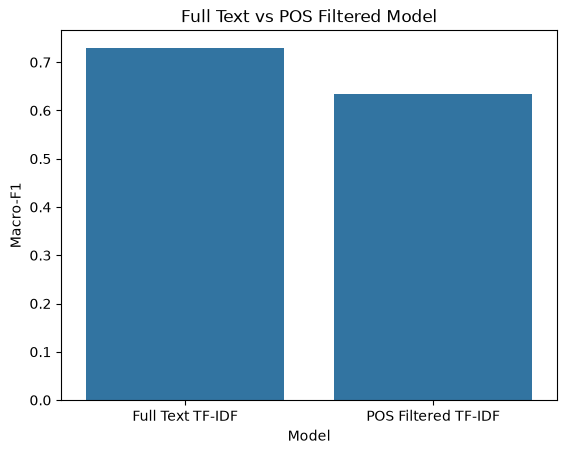

In [137]:
pos_comparison = pd.DataFrame({

    "Model": [
        "Full Text TF-IDF",
        "POS Filtered TF-IDF"
    ],

    "Macro-F1": [
        full_text_f1,
        pos_f1
    ]

})

display(pos_comparison)

sns.barplot(
    data=pos_comparison,
    x="Model",
    y="Macro-F1"
)

plt.title("Full Text vs POS Filtered Model")
plt.show()

In [138]:
deployment_pipeline = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            min_df=2
        )
    ),

    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )

])

deployment_pipeline.fit(
    X_train,
    y_train
)

joblib.dump(
    deployment_pipeline,
    "sentiment_model.joblib"
)

print("Deployment model saved successfully!")

Deployment model saved successfully!


In [139]:
test_model = joblib.load(
    "sentiment_model.joblib"
)

test_sentences = [
    "The flight was amazing",
    "My luggage was lost",
    "The flight was okay"
]

for sentence in test_sentences:

    cleaned = clean_text(sentence)

    prediction = test_model.predict([
        cleaned
    ])[0]

    probabilities = test_model.predict_proba([
        cleaned
    ])[0]

    print("\nSentence:", sentence)
    print("Prediction:", prediction)
    print("Probabilities:", probabilities)


Sentence: The flight was amazing
Prediction: positive
Probabilities: [0.06968292 0.07451727 0.85579981]

Sentence: My luggage was lost
Prediction: negative
Probabilities: [0.88131253 0.05185318 0.06683429]

Sentence: The flight was okay
Prediction: negative
Probabilities: [0.42900751 0.42080337 0.15018912]


In [140]:
import sklearn
import pandas
import numpy
import nltk
import gensim
import joblib
import streamlit

requirements = [
    f"streamlit=={streamlit.__version__}",
    f"scikit-learn=={sklearn.__version__}",
    f"nltk=={nltk.__version__}",
    f"pandas=={pandas.__version__}",
    f"numpy=={numpy.__version__}",
    f"joblib=={joblib.__version__}"
]

with open(
    "requirements.txt",
    "w"
) as file:

    file.write(
        "\n".join(requirements)
    )

print("requirements.txt created!")

print("\n".join(requirements))

requirements.txt created!
streamlit==1.67.0
scikit-learn==1.9.1
nltk==3.9.4
pandas==3.0.6
numpy==2.4.6
joblib==1.5.3
